In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter



First 20 curve IDs:
'IVF-2-27-1'
'IVF-2-23-1'
'IVF-4-93-1'
'IVF-4-73-2'
'IVF-2-49-2'
'IVF-2-3-1'
'IVF-4-99-3'
'IVF-4-95-3'
'IVF-4-91-3'
'IVF-4-71-4'
'IVF-4-46-2'
'IVF-4-121-2'
'IVF-2-159-1'
'IVF-2-131-2'
'IVF-4-48-4'
'IVF-4-44-4'
'IVF-2C-Pseudobulk'
'IVF-1C-52'
'IVF-4-98-1'
'IVF-4-90-1'

Genomic distance:
[      0.  500000. 1000000. 1500000. 2000000. 2500000. 3000000. 3500000.
 4000000. 4500000.]

Number of distance bins: 41
Distance range: 0.0 - 20000000.0

Bulk/Pseudobulk IDs found:
'IVF-2C-Pseudobulk'
'IVF-4C-Bulk'
'IVF-Zygote-Bulk'


/home/lihaoxing/tmp/ipykernel_1040792/3910209032.py:184: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))


Found: IVF-Zygote-Bulk
Found: IVF-2C-Pseudobulk
Found: IVF-4C-Bulk


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['DejaVu Sans Display'] not found. Falling back to DejaVu Sans.


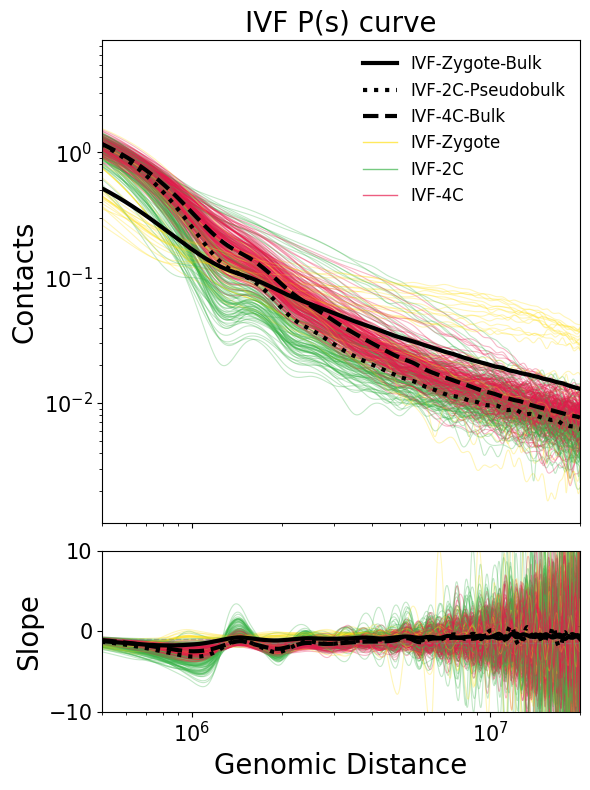

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import numpy as np


# ============================================================
# Matplotlib settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 1. Read P(s) data
# ============================================================
data = pd.read_csv(
    'IVF_350_Ps_curve_new.txt',
    sep='\t',
    index_col=0,
    encoding='utf-8-sig'
)


# ============================================================
# 2. IMPORTANT
#
# The real curve ID is the DataFrame index.
#
# The first data column named "ID" corresponds to genomic
# distance = 0.
# ============================================================

data.index = (
    data.index
    .astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.replace('\r', '', regex=False)
    .str.replace('\n', '', regex=False)
    .str.strip()
)


print("\nFirst 20 curve IDs:")
for curve_id in data.index[:20]:
    print(repr(curve_id))


# ============================================================
# 3. Convert column names
#
# "ID" is actually genomic distance 0
# ============================================================
distance_columns = []

for col in data.columns:

    if col == 'ID':
        distance_columns.append(0)

    else:
        distance_columns.append(
            float(col)
        )


data.columns = distance_columns


# ============================================================
# 4. Sort genomic distances
# ============================================================
data = data.sort_index(axis=1)


# ============================================================
# 5. X-axis
# ============================================================
x = np.array(
    data.columns,
    dtype=float
)

x_new = np.linspace(
    x.min(),
    x.max(),
    5000
)


print("\nGenomic distance:")
print(x[:10])

print(
    f"\nNumber of distance bins: {len(x)}"
)

print(
    f"Distance range: {x.min()} - {x.max()}"
)


# ============================================================
# 6. Check bulk / pseudobulk IDs
# ============================================================
print("\nBulk/Pseudobulk IDs found:")

for curve_id in data.index:

    if (
        'Bulk' in curve_id
        or 'Pseudobulk' in curve_id
    ):
        print(
            repr(curve_id)
        )


# ============================================================
# 7. Single-cell data
# ============================================================
selected_data = data.iloc[:352]


# ============================================================
# 8. Figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(6, 8),
    gridspec_kw={
        'height_ratios': [3, 1]
    }
)


# ============================================================
# 9. Single-cell colors
# ============================================================
cell_colors = {
    'IVF-Zygote': '#ffe119',
    'IVF-2C': '#3cb44b',
    'IVF-4C': '#e6194b'
}


legend_added = {
    'IVF-Zygote': False,
    'IVF-2C': False,
    'IVF-4C': False
}


handles = []
labels = []


# ============================================================
# 10. Calculate P(s) slope
# ============================================================
def calculate_slope(x, y):

    spline = make_interp_spline(
        x,
        y,
        k=3
    )

    y_smooth = spline(
        x_new
    )

    # Avoid invalid values
    y_smooth = np.where(
        y_smooth <= 0,
        np.nan,
        y_smooth
    )

    slope = np.gradient(
        np.log(y_smooth),
        np.log(x_new)
    )

    return y_smooth, slope


# ============================================================
# 11. Plot single-cell curves
# ============================================================
for curve_id, row in selected_data.iterrows():

    y = row.values.astype(float)


    # Skip invalid curves
    if not np.isfinite(y).all():
        continue


    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------
    if curve_id.startswith('IVF-1C'):

        label = 'IVF-Zygote'

    elif curve_id.startswith('IVF-2-'):

        label = 'IVF-2C'

    elif curve_id.startswith('IVF-4-'):

        label = 'IVF-4C'

    else:

        continue


    color = cell_colors[label]


    try:

        y_smooth, slope = calculate_slope(
            x,
            y
        )


        # First curve of each group
        if not legend_added[label]:

            line, = ax1.plot(
                x_new,
                y_smooth,
                color=color,
                alpha=0.7,
                linewidth=1
            )

            ax2.plot(
                x_new,
                slope,
                color=color,
                alpha=0.7,
                linewidth=1
            )

            legend_added[label] = True

            handles.append(
                line
            )

            labels.append(
                label
            )


        # Remaining cells
        else:

            ax1.plot(
                x_new,
                y_smooth,
                color=color,
                alpha=0.3,
                linewidth=0.8
            )

            ax2.plot(
                x_new,
                slope,
                color=color,
                alpha=0.3,
                linewidth=0.8
            )


    except Exception as e:

        print(
            f'Error: {curve_id} -> {e}'
        )


# ============================================================
# 12. Bulk / Pseudobulk
# ============================================================
bulk_ids = [
    'IVF-Zygote-Bulk',
    'IVF-2C-Pseudobulk',
    'IVF-4C-Bulk'
]


bulk_styles = {
    'IVF-Zygote-Bulk': '-',
    'IVF-2C-Pseudobulk': ':',
    'IVF-4C-Bulk': '--'
}


# ============================================================
# 13. Plot bulk / pseudobulk
# ============================================================
for bulk_id in bulk_ids:

    # Use index because index = actual curve ID
    if bulk_id not in data.index:

        print(
            f'WARNING: {bulk_id} not found!'
        )

        continue


    print(
        f'Found: {bulk_id}'
    )


    # Extract curve
    y_bulk = (
        data.loc[bulk_id]
        .values
        .astype(float)
    )


    if not np.isfinite(y_bulk).all():

        print(
            f'WARNING: {bulk_id} contains invalid values.'
        )

        continue


    try:

        y_bulk_smooth, slope_bulk = calculate_slope(
            x,
            y_bulk
        )


        linestyle = bulk_styles[
            bulk_id
        ]


        # ----------------------------------------------------
        # Main P(s)
        # ----------------------------------------------------
        line_bulk, = ax1.plot(
            x_new,
            y_bulk_smooth,
            color='black',
            linewidth=3,
            linestyle=linestyle,
            zorder=10
        )


        # ----------------------------------------------------
        # Slope
        # ----------------------------------------------------
        ax2.plot(
            x_new,
            slope_bulk,
            color='black',
            linewidth=3,
            linestyle=linestyle,
            zorder=10
        )


        handles.append(
            line_bulk
        )

        labels.append(
            bulk_id
        )


    except Exception as e:

        print(
            f'Error processing {bulk_id}: {e}'
        )


# ============================================================
# 14. Legend order
# ============================================================
desired_order = [
    'IVF-Zygote-Bulk',
    'IVF-2C-Pseudobulk',
    'IVF-4C-Bulk',
    'IVF-Zygote',
    'IVF-2C',
    'IVF-4C'
]


ordered_handles = [
    handles[labels.index(name)]
    for name in desired_order
    if name in labels
]


ordered_labels = [
    name
    for name in desired_order
    if name in labels
]


# ============================================================
# 15. Main P(s) panel
# ============================================================
ax1.set_xscale('log')
ax1.set_yscale('log')

ax1.set_xlim(
    500000,
    20000000
)

ax1.set_xticklabels([])

ax1.tick_params(
    axis='both',
    which='major',
    labelsize=15
)

ax1.set_ylabel(
    'Contacts',
    fontsize=20
)

ax1.set_title(
    'IVF P(s) curve',
    fontsize=20
)


if ordered_handles:

    ax1.legend(
        ordered_handles,
        ordered_labels,
        fontsize=12,
        loc='best',
        frameon=False
    )


# ============================================================
# 16. Slope panel
# ============================================================
ax2.set_xscale('log')

ax2.set_xlim(
    500000,
    20000000
)

ax2.set_ylim(
    -10,
    10
)

ax2.tick_params(
    axis='both',
    which='major',
    labelsize=15
)

ax2.set_xlabel(
    'Genomic Distance',
    fontsize=20
)

ax2.set_ylabel(
    'Slope',
    fontsize=20
)


# Reference lines
ax2.axhline(
    -1,
    linestyle='--',
    color='gray',
    alpha=0.5,
    linewidth=1
)

ax2.axhline(
    -1.5,
    linestyle='--',
    color='gray',
    alpha=0.5,
    linewidth=1
)


# ============================================================
# 17. Layout
# ============================================================
plt.tight_layout()


# ============================================================
# 18. Save
# ============================================================
plt.savefig(
    'IVF_350_ps_curves_and_slopes.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)


plt.show()

In [5]:
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# =============================
# 读取数据
# =============================
data = pd.read_csv('IVF_350_Ps_curve_new.txt', sep='\t')
data['ID'] = data['ID'].str.strip()

# =============================
# 横坐标
# =============================
x = data.columns[1:].astype(float)
x_new = np.linspace(x.min(), x.max(), 500)

# =============================
# 特征提取（log P(s)）
# =============================
def extract_feature(row):

    y = row.values[1:].astype(float)

    if not np.isfinite(y).all():
        return None

    try:
        # spline 平滑
        spl = make_interp_spline(x, y, k=3)
        y_smooth = spl(x_new)

        # 限制距离范围（关键）
        mask = (x_new >= 5e5) & (x_new <= 2e7)
        y_use = y_smooth[mask]

        # 避免 log 崩溃
        eps = 1e-10
        y_use = np.clip(y_use, eps, None)

        # log 转换
        y_log = np.log(y_use)

        # 标准化（只保留形状）
        y_log = (y_log - np.mean(y_log)) / (np.std(y_log) + 1e-8)

        if not np.isfinite(y_log).all():
            return None

        return y_log

    except:
        return None


# =============================
# 稳定KMeans
# =============================
def stable_kmeans(features, n_runs=6, k=2, threshold=4):

    all_labels = []

    for seed in range(n_runs):
        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = kmeans.fit_predict(features)
        all_labels.append(labels)

    all_labels = np.array(all_labels)

    final_labels = []

    for i in range(all_labels.shape[1]):
        votes = all_labels[:, i]

        counts = np.bincount(votes, minlength=k)
        max_count = counts.max()
        majority = counts.argmax()

        if max_count >= threshold:
            final_labels.append(int(majority))
        else:
            final_labels.append("Undefined")

    return np.array(final_labels)


# =============================
# 主流程
# =============================
output_all = []

for stage in ["IVF-2-", "IVF-4-"]:

    subset = data[data['ID'].str.startswith(stage)]

    features = []
    raw_curves = []
    valid_ids = []

    for _, row in subset.iterrows():
        feat = extract_feature(row)
        if feat is not None:
            features.append(feat)
            valid_ids.append(row['ID'])

            # 用于排序cluster（不标准化）
            y = row.values[1:].astype(float)
            y = np.clip(y, 1e-10, None)
            raw_curves.append(np.log(y))

    features = np.array(features)
    raw_curves = np.array(raw_curves)

    # 防NaN
    mask = np.isfinite(features).all(axis=1)
    features = features[mask]
    raw_curves = raw_curves[mask]
    valid_ids = np.array(valid_ids)[mask]

    print(f"{stage} cells: {len(valid_ids)}")

    # PCA降维（增强稳定性）
    if features.shape[0] > 10:
        pca = PCA(n_components=10)
        features = pca.fit_transform(features)

    # =============================
    # 稳定聚类
    # =============================
    labels = stable_kmeans(features)

    # =============================
    # cluster排序（确保ps1/ps2稳定）
    # =============================
    cluster_means = {}

    for c in [0, 1]:
        idx = (labels == c)
        if idx.sum() > 0:
            cluster_means[c] = raw_curves[idx].mean()
        else:
            cluster_means[c] = np.nan

    # 按均值排序（低 → 高）
    sorted_clusters = sorted(cluster_means, key=cluster_means.get)

    # =============================
    # 命名规则（你指定的格式）
    # =============================
    if stage == "IVF-2-":
        name_map = {
            sorted_clusters[0]: "IVF-2C-ps1",
            sorted_clusters[1]: "IVF-2C-ps2"
        }
    elif stage == "IVF-4-":
        name_map = {
            sorted_clusters[0]: "IVF-4C-ps1",
            sorted_clusters[1]: "IVF-4C-ps2"
        }

    # 生成最终标签
    final_names = []
    for lab in labels:
        if lab == "Undefined":
            final_names.append("Undefined")
        else:
            final_names.append(name_map[lab])

    df_stage = pd.DataFrame({
        "ID": valid_ids,
        "Category": final_names
    })

    output_all.append(df_stage)


# =============================
# =============================
# 合并
# =============================
final_df = pd.concat(output_all, ignore_index=True)

# =============================
# 分别输出
# =============================
df_2c = final_df[final_df['ID'].str.startswith("IVF-2-")]
df_4c = final_df[final_df['ID'].str.startswith("IVF-4-")]

df_2c.to_csv("IVF-2C_ps_clusters.txt", sep='\t', index=False)
df_4c.to_csv("IVF-4C_ps_clusters.txt", sep='\t', index=False)

print("✅ 输出完成：")
print(" - IVF-2C_ps_clusters.txt")
print(" - IVF-4C_ps_clusters.txt")

IVF-2- cells: 109
IVF-4- cells: 210
✅ 输出完成：
 - IVF-2C_ps_clusters.txt
 - IVF-4C_ps_clusters.txt



=== IVF 2C UMAP (ps curve) 各类别细胞数量 ===
IVF-2C-ps1: 93
IVF-2C-ps2: 16



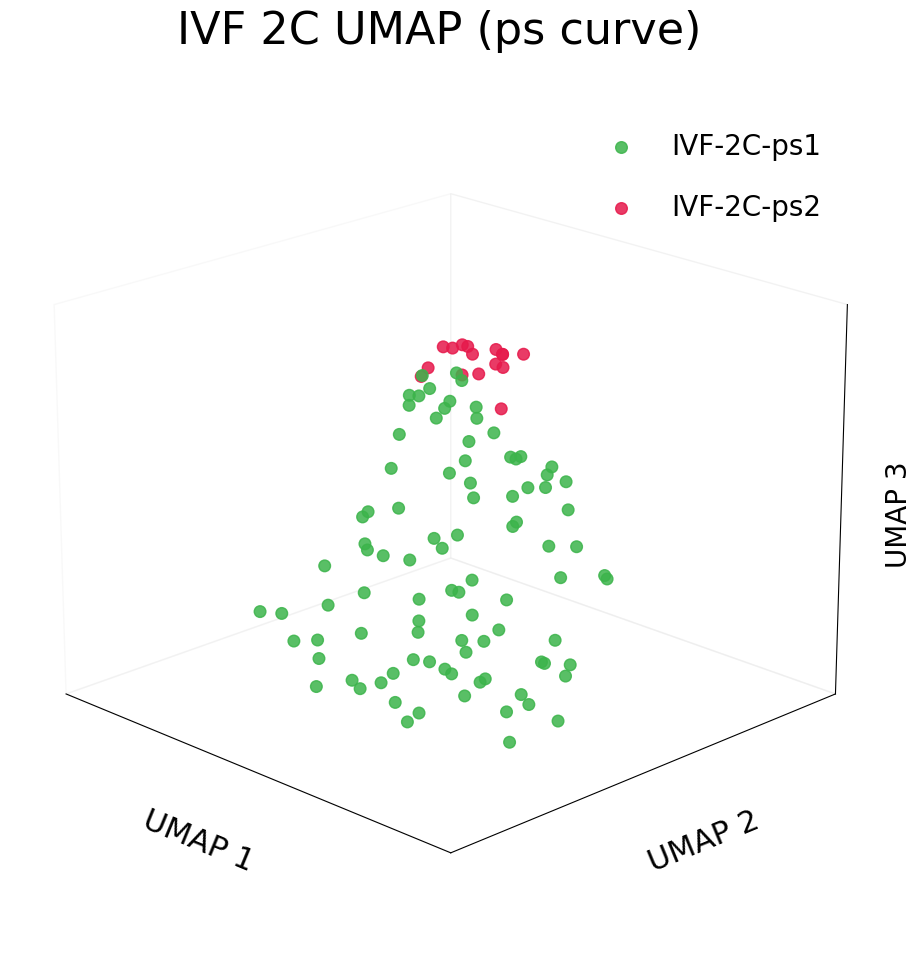


=== IVF 4C UMAP (ps curve) 各类别细胞数量 ===
IVF-4C-ps1: 152
IVF-4C-ps2: 58



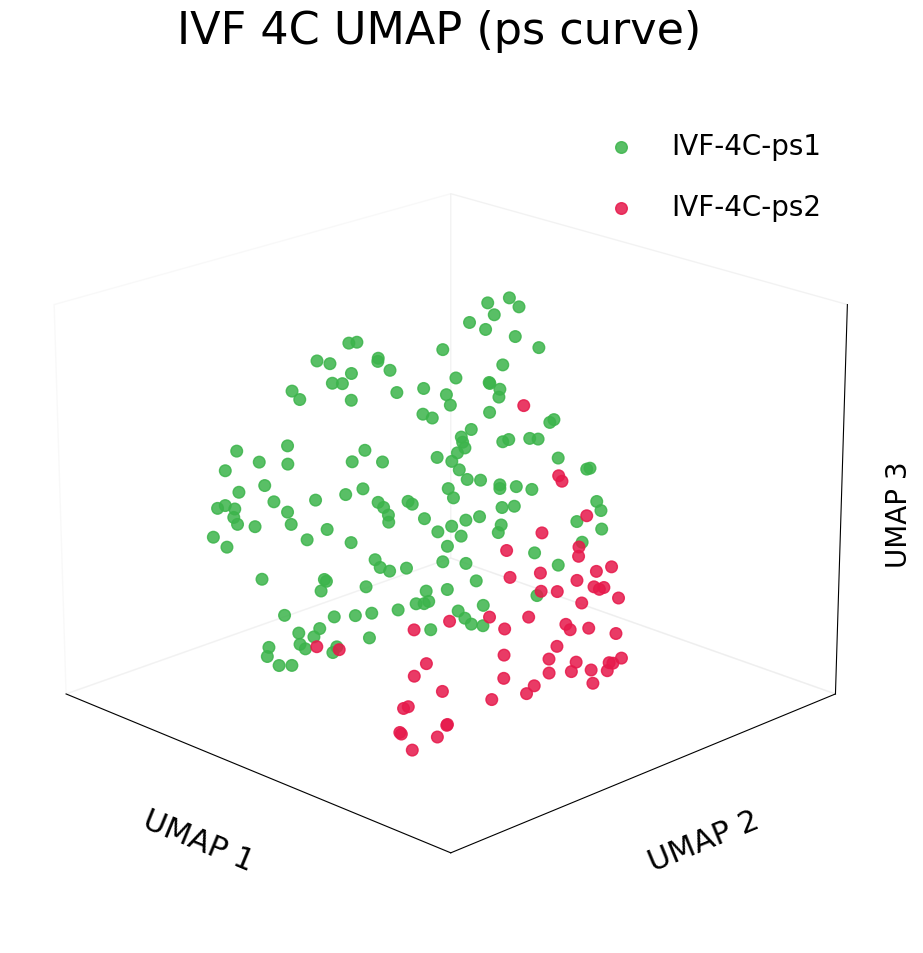

In [6]:
import umap
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 3D UMAP 可视化函数
# =============================
def plot_umap_3d(features, labels, title, save_path=None):
    
    # =========================
    # 打印各类别细胞数量
    # =========================
    unique_labels, counts = np.unique(labels, return_counts=True)
    print(f"\n=== {title} 各类别细胞数量 ===")
    for lab, cnt in zip(unique_labels, counts):
        print(f"{lab}: {cnt}")
    print("===========================\n")

    reducer = umap.UMAP(
        n_components=3,
        n_neighbors=15,
        min_dist=0.2,
        metric='euclidean',
        random_state=42
    )

    embedding = reducer.fit_transform(features)

    labels = np.array(labels)

    # =========================
    # 颜色定义（统一风格）
    # =========================
    color_map = {
        "IVF-2C-ps1": "#3cb44b",
        "IVF-2C-ps2": "#e6194b",
        "IVF-4C-ps1": "#3cb44b",
        "IVF-4C-ps2": "#e6194b",
        "Undefined": "gray"
    }

    # =========================
    # 全局字体（论文级）
    # =========================
    plt.rcParams.update({
        "font.size": 22,
        "axes.titlesize": 32,
        "axes.labelsize": 22,
        "legend.fontsize": 20
    })

    # =========================
    # 画图
    # =========================
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    for lab in np.unique(labels):
        idx = labels == lab

        ax.scatter(
            embedding[idx, 0],
            embedding[idx, 1],
            embedding[idx, 2],
            s=70,                 # ✅ 更大点
            alpha=0.85,
            c=color_map.get(lab, "black"),
            label=lab
        )

    # =========================
    # 关键：视角优化
    # =========================
    ax.view_init(elev=20, azim=135)

    # =========================
    # 标题 & 坐标轴
    # =========================
    ax.set_title(title, pad=30)

    ax.set_xlabel("UMAP 1", labelpad=20)
    ax.set_ylabel("UMAP 2", labelpad=20)

    # ❗不要用 zlabel（会被裁剪）
    ax.set_zlabel("")

    # ✅ 永不裁剪方案（核心）
    ax.text2D(
        1.02, 0.5, "UMAP 3",
        transform=ax.transAxes,
        fontsize=20,
        rotation=90,
        va='center'
    )

    # =========================
    # 去刻度（更干净）
    # =========================
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

    # =========================
    # 去背景（更高级）
    # =========================
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    # =========================
    # 图例优化
    # =========================
    ax.legend(
        loc='upper right',
        frameon=False,
        borderpad=1.2,
        labelspacing=1.2
    )

    # =========================
    # 防裁剪
    # =========================
    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches='tight',
            transparent=True
        )

    plt.show()


# =============================
# IVF-2C UMAP
# =============================
df_2c = final_df[final_df['ID'].str.startswith("IVF-2-")].copy()

features_2c = []
labels_2c = []

for _, row in df_2c.iterrows():

    feat = extract_feature(data[data['ID'] == row['ID']].iloc[0])
    if feat is None:
        continue

    features_2c.append(feat)
    labels_2c.append(row['Category'])

features_2c = np.array(features_2c)

plot_umap_3d(features_2c, labels_2c, "IVF 2C UMAP (ps curve)",save_path="IVF_2C_UMAP_ps.svg")


# =============================
# IVF-4C UMAP
# =============================
df_4c = final_df[final_df['ID'].str.startswith("IVF-4-")].copy()

features_4c = []
labels_4c = []

for _, row in df_4c.iterrows():

    feat = extract_feature(data[data['ID'] == row['ID']].iloc[0])
    if feat is None:
        continue

    features_4c.append(feat)
    labels_4c.append(row['Category'])

features_4c = np.array(features_4c)

plot_umap_3d(features_4c, labels_4c, "IVF 4C UMAP (ps curve)",save_path="IVF_4C_UMAP_ps.svg")

/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxin

/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxin

/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxin

/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxin

/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxing/tmp/ipykernel_1040792/4146299302.py:141: RuntimeWarning: divide by zero encountered in log
  np.log(x_new)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1241: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/home/lihaoxin

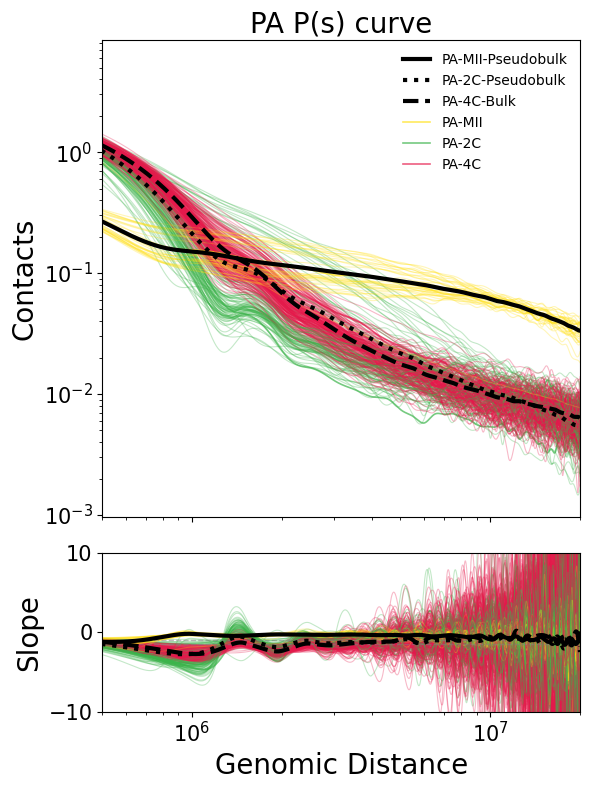

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import numpy as np
from IPython.display import SVG, display


# ============================================================
# Matplotlib settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 读取数据
# ============================================================
data = pd.read_csv(
    'PA_334_Ps_curve_new.txt',
    sep='\t'
)

# 清理 ID
data['ID'] = data['ID'].astype(str).str.strip()


# ============================================================
# 横坐标
# ============================================================
x = data.columns[1:].astype(int).values

x_new = np.linspace(
    x.min(),
    x.max(),
    5000
)


# ============================================================
# 单细胞数据
# ============================================================
selected_data = data.head(355)


# ============================================================
# Figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(6, 8),
    gridspec_kw={'height_ratios': [3, 1]}
)


# ============================================================
# 单细胞颜色
# ============================================================
cell_colors = {
    'PA-MII': '#ffe119',
    'PA-2C': '#3cb44b',
    'PA-4C': '#e6194b'
}


# ============================================================
# Legend
# ============================================================
handles = []
labels = []

legend_added = {
    'PA-MII': False,
    'PA-2C': False,
    'PA-4C': False
}


# ============================================================
# 单细胞曲线
# ============================================================
for _, row in selected_data.iterrows():

    curve_id = row['ID']

    y = row.iloc[1:].astype(float).values

    # --------------------------------------------------------
    # 检查数据
    # --------------------------------------------------------
    if not np.isfinite(y).all():
        continue

    # --------------------------------------------------------
    # 分类
    # --------------------------------------------------------
    if curve_id.startswith('PA-MII'):

        group = 'PA-MII'

    elif curve_id.startswith('PA-2C'):

        group = 'PA-2C'

    elif curve_id.startswith('PA-4C'):

        group = 'PA-4C'

    else:

        continue

    color = cell_colors[group]

    # --------------------------------------------------------
    # Spline interpolation
    # --------------------------------------------------------
    try:

        spl = make_interp_spline(
            x,
            y,
            k=3
        )

        y_smooth = spl(x_new)

        # 防止 log 出现 <= 0
        y_smooth = np.where(
            y_smooth <= 0,
            np.nan,
            y_smooth
        )

        # ----------------------------------------------------
        # slope = dlog(P(s)) / dlog(s)
        # ----------------------------------------------------
        slope = np.gradient(
            np.log(y_smooth),
            np.log(x_new)
        )

        # ----------------------------------------------------
        # 第一条曲线加入 legend
        # ----------------------------------------------------
        if not legend_added[group]:

            line, = ax1.plot(
                x_new,
                y_smooth,
                color=color,
                alpha=0.7,
                linewidth=1.2
            )

            ax2.plot(
                x_new,
                slope,
                color=color,
                alpha=0.7,
                linewidth=1.2
            )

            handles.append(line)
            labels.append(group)

            legend_added[group] = True

        else:

            ax1.plot(
                x_new,
                y_smooth,
                color=color,
                alpha=0.3,
                linewidth=0.8
            )

            ax2.plot(
                x_new,
                slope,
                color=color,
                alpha=0.3,
                linewidth=0.8
            )

    except Exception as e:

        print(
            f'Error: {curve_id} -> {e}'
        )


# ============================================================
# Bulk / Pseudobulk
# ============================================================

bulk_ids = [
    'PA-MII-Pseudobulk',
    'PA-2C-Pseudobulk',
    'PA-4C-Bulk'
]


# ============================================================
# 线型
# ============================================================

bulk_styles = {
    'PA-MII-Pseudobulk': '-',
    'PA-2C-Pseudobulk': ':',
    'PA-4C-Bulk': '--'
}


# ============================================================
# 线宽
# ============================================================

bulk_linewidths = {
    'PA-MII-Pseudobulk': 3,
    'PA-2C-Pseudobulk': 3,
    'PA-4C-Bulk': 3
}


# ============================================================
# 绘制 Bulk / Pseudobulk
# ============================================================

for bulk_id in bulk_ids:

    bulk_row = data[data['ID'] == bulk_id]

    # --------------------------------------------------------
    # 检查是否存在
    # --------------------------------------------------------
    if bulk_row.empty:

        print(
            f'{bulk_id} not found!'
        )

        continue

    # --------------------------------------------------------
    # 提取数据
    # --------------------------------------------------------
    y_bulk = bulk_row.iloc[0, 1:].astype(float).values

    # --------------------------------------------------------
    # 检查数据
    # --------------------------------------------------------
    if not np.isfinite(y_bulk).all():

        print(
            f'{bulk_id} contains invalid values.'
        )

        continue

    try:

        # ----------------------------------------------------
        # Spline interpolation
        # ----------------------------------------------------
        spl_bulk = make_interp_spline(
            x,
            y_bulk,
            k=3
        )

        y_bulk_smooth = spl_bulk(x_new)

        # 防止 log 出现 <= 0
        y_bulk_smooth = np.where(
            y_bulk_smooth <= 0,
            np.nan,
            y_bulk_smooth
        )

        # ----------------------------------------------------
        # slope
        # ----------------------------------------------------
        slope_bulk = np.gradient(
            np.log(y_bulk_smooth),
            np.log(x_new)
        )

        linestyle = bulk_styles[bulk_id]
        linewidth = bulk_linewidths[bulk_id]

        # ----------------------------------------------------
        # P(s) curve
        # ----------------------------------------------------
        line_bulk, = ax1.plot(
            x_new,
            y_bulk_smooth,
            color='black',
            linewidth=linewidth,
            linestyle=linestyle,
            zorder=10
        )

        # ----------------------------------------------------
        # Slope
        # ----------------------------------------------------
        ax2.plot(
            x_new,
            slope_bulk,
            color='black',
            linewidth=linewidth,
            linestyle=linestyle,
            zorder=10
        )

        # ----------------------------------------------------
        # 加入 legend
        # ----------------------------------------------------
        handles.append(line_bulk)
        labels.append(bulk_id)

    except Exception as e:

        print(
            f'Error in {bulk_id}: {e}'
        )


# ============================================================
# Legend顺序
# ============================================================

desired_order = [

    # Pseudobulk / Bulk
    'PA-MII-Pseudobulk',
    'PA-2C-Pseudobulk',
    'PA-4C-Bulk',

    # Single cells
    'PA-MII',
    'PA-2C',
    'PA-4C'
]


ordered_handles = [
    handles[labels.index(name)]
    for name in desired_order
    if name in labels
]

ordered_labels = [
    name
    for name in desired_order
    if name in labels
]


# ============================================================
# 上图：P(s)
# ============================================================

ax1.set_xscale('log')
ax1.set_yscale('log')

ax1.set_xlim(
    500000,
    20000000
)

# 隐藏上图 x-axis labels
ax1.set_xticklabels([])

ax1.tick_params(
    axis='both',
    which='major',
    labelsize=15
)

ax1.set_ylabel(
    'Contacts',
    fontsize=20
)

ax1.set_title(
    'PA P(s) curve',
    fontsize=20
)


# ============================================================
# Legend
# ============================================================

ax1.legend(
    handles=ordered_handles,
    labels=ordered_labels,
    fontsize=10,
    loc='best',
    frameon=False
)


# ============================================================
# 下图：Slope
# ============================================================

ax2.set_xscale('log')

ax2.set_xlim(
    500000,
    20000000
)

ax2.set_ylim(
    -10,
    10
)

ax2.tick_params(
    axis='both',
    which='major',
    labelsize=15
)

ax2.set_xlabel(
    'Genomic Distance',
    fontsize=20
)

ax2.set_ylabel(
    'Slope',
    fontsize=20
)


# ============================================================
# Reference lines
# ============================================================

ax2.axhline(
    -1,
    linestyle='--',
    color='gray',
    alpha=0.5,
    linewidth=1
)

ax2.axhline(
    -1.5,
    linestyle='--',
    color='gray',
    alpha=0.5,
    linewidth=1
)


# ============================================================
# Layout
# ============================================================

plt.tight_layout()


# ============================================================
# 保存 SVG
# ============================================================

plt.savefig(
    'PA_334_ps_curves_and_slopes.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)


# ============================================================
# 显示
# ============================================================

plt.show()

In [8]:
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# =============================
# 读取数据
# =============================
data = pd.read_csv('PA_334_Ps_curve_new_celltype.txt', sep='\t')
data['ID'] = data['ID'].str.strip()

x = data.columns[2:].astype(float)
x_new = np.linspace(x.min(), x.max(), 500)


# =============================
# 特征提取
# =============================
def extract_feature(row):
    y = row.values[2:].astype(float)

    if not np.isfinite(y).all():
        return None

    try:
        spl = make_interp_spline(x, y, k=3)
        y_smooth = spl(x_new)

        mask = (x_new >= 5e5) & (x_new <= 2e7)
        y_use = y_smooth[mask]

        y_use = np.clip(y_use, 1e-10, None)
        y_log = np.log(y_use)

        y_log = (y_log - np.mean(y_log)) / (np.std(y_log) + 1e-8)

        if not np.isfinite(y_log).all():
            return None

        return y_log

    except:
        return None


# =============================
# 稳定KMeans（修复版）
# =============================
def stable_kmeans(features, n_runs=10, k=2):
    features = np.array(features)

    all_labels = []

    for seed in range(n_runs):
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = km.fit_predict(features)
        all_labels.append(labels)

    all_labels = np.array(all_labels)

    # majority vote per cell
    final = []

    for i in range(all_labels.shape[1]):
        votes = all_labels[:, i]

        counts = np.bincount(votes, minlength=k)
        final.append(int(np.argmax(counts)))

    return np.array(final)


# =============================
# 主流程
# =============================
output_all = []

for stage in ["PA-2C", "PA-4C"]:

    subset = data[data['celltype'] == stage]

    features = []
    ids = []
    raw = []

    for _, row in subset.iterrows():
        feat = extract_feature(row)
        if feat is None:
            continue

        features.append(feat)
        ids.append(row['ID'])

        y = row.values[2:].astype(float)
        raw.append(np.log(np.clip(y, 1e-10, None)))

    features = np.array(features)
    raw = np.array(raw)
    ids = np.array(ids)

    print(stage, "cells:", len(ids))

    # PCA
    if len(features) > 10:
        features = PCA(n_components=10).fit_transform(features)

    # =============================
    # clustering
    # =============================
    labels = stable_kmeans(features)

    # =============================
    # cluster排序（用median！）
    # =============================
    cluster_score = {}

    for c in np.unique(labels):
        cluster_score[c] = np.median(raw[labels == c])

    sorted_clusters = sorted(cluster_score, key=cluster_score.get)

    # naming
    if stage == "PA-2C":
        name_map = {
            sorted_clusters[0]: "PA-2C-ps1",
            sorted_clusters[1]: "PA-2C-ps2"
        }
    else:
        name_map = {
            sorted_clusters[0]: "PA-4C-ps1",
            sorted_clusters[1]: "PA-4C-ps2"
        }

    final_names = [name_map[l] for l in labels]

    df = pd.DataFrame({
        "ID": ids,
        "Category": final_names
    })

    output_all.append(df)


# =============================
# 输出
# =============================
final_df = pd.concat(output_all)

final_df[final_df['ID'].str.startswith("2-")].to_csv("PA-2C_ps_clusters.txt", sep='\t', index=False)
final_df[final_df['ID'].str.startswith("4-")].to_csv("PA-4C_ps_clusters.txt", sep='\t', index=False)

print("OK")

PA-2C cells: 107
PA-4C cells: 192
OK


PA-2C cells: 107
PA-4C cells: 192
Category
PA-2C-ps1     84
PA-2C-ps2     23
PA-4C-ps1    119
PA-4C-ps2     73
dtype: int64


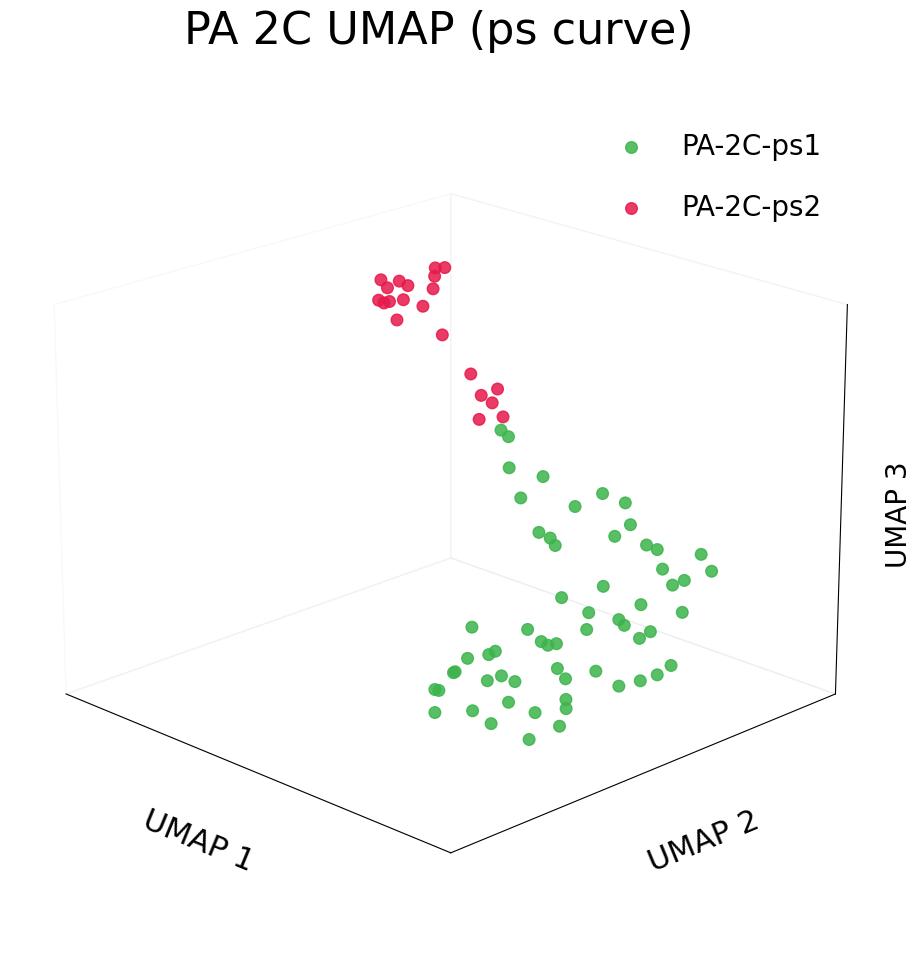

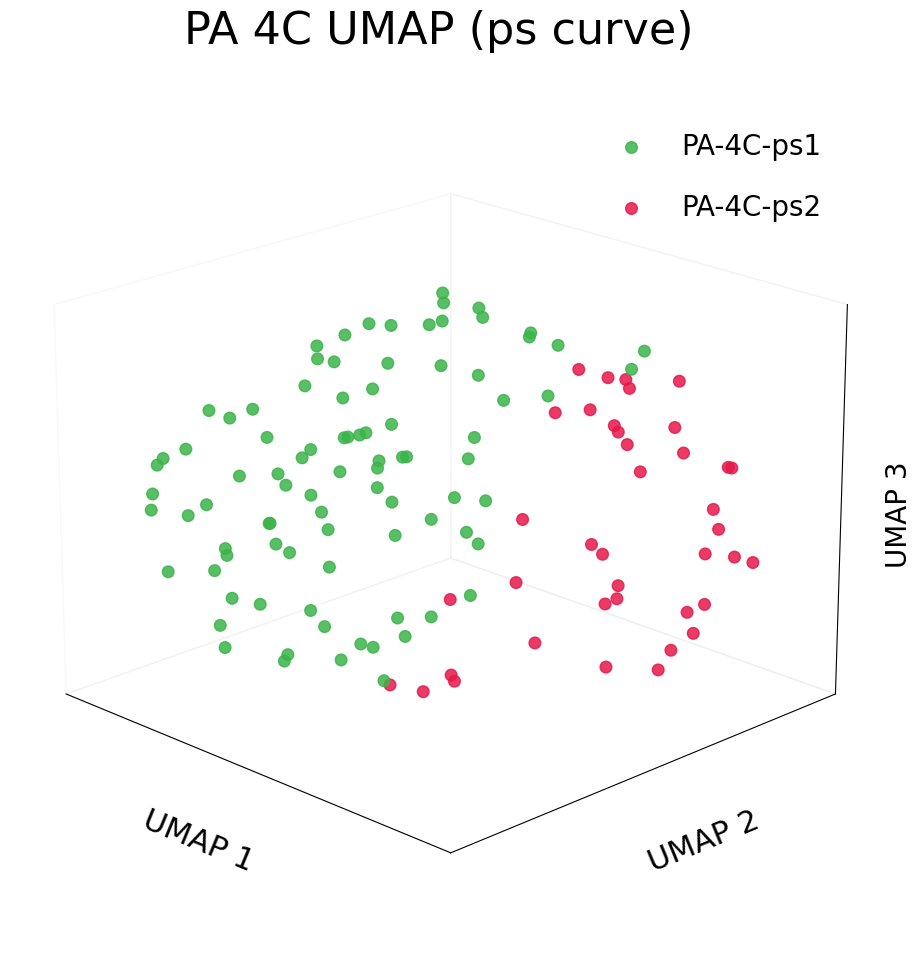

In [9]:
import pandas as pd
import numpy as np
import umap
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.interpolate import make_interp_spline
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =============================
# 读取数据
# =============================
data = pd.read_csv('PA_334_Ps_curve_new_celltype.txt', sep='\t')
data['ID'] = data['ID'].str.strip()

x = data.columns[2:].astype(float)
x_new = np.linspace(x.min(), x.max(), 500)

# =============================
# feature 提取（只算一次）
# =============================
def extract_feature(row):

    y = row.values[2:].astype(float)

    if not np.isfinite(y).all():
        return None

    try:
        spl = make_interp_spline(x, y, k=3)
        y_smooth = spl(x_new)

        mask = (x_new >= 5e5) & (x_new <= 2e7)
        y_use = y_smooth[mask]

        y_use = np.clip(y_use, 1e-10, None)
        y_log = np.log(y_use)

        y_log = (y_log - np.mean(y_log)) / (np.std(y_log) + 1e-8)

        if not np.isfinite(y_log).all():
            return None

        return y_log

    except:
        return None


# =============================
# feature缓存（关键优化）
# =============================
feature_dict = {}

for _, row in data.iterrows():
    feat = extract_feature(row)
    if feat is not None:
        feature_dict[row['ID']] = feat


# =============================
# 稳定KMeans
# =============================
def stable_kmeans(X, n_runs=8, k=2):

    X = np.array(X)
    all_labels = []

    for seed in range(n_runs):
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        all_labels.append(km.fit_predict(X))

    all_labels = np.array(all_labels)

    final = []

    for i in range(all_labels.shape[1]):
        votes = all_labels[:, i]
        counts = np.bincount(votes, minlength=k)
        final.append(int(np.argmax(counts)))

    return np.array(final)


# =============================
# 3D UMAP
# =============================
def plot_umap_3d(features, labels, title, save_path=None):

    reducer = umap.UMAP(
        n_components=3,
        n_neighbors=15,
        min_dist=0.2,
        metric='euclidean',
        random_state=42
    )

    embedding = reducer.fit_transform(features)

    labels = np.array(labels)

    # =========================
    # 颜色定义（统一风格）
    # =========================
    color_map = {
        "PA-2C-ps1": "#3cb44b",
        "PA-2C-ps2": "#e6194b",
        "PA-4C-ps1": "#3cb44b",
        "PA-4C-ps2": "#e6194b",
        "Undefined": "gray"
    }

    # =========================
    # 全局字体（论文级）
    # =========================
    plt.rcParams.update({
        "font.size": 22,
        "axes.titlesize": 32,
        "axes.labelsize": 22,
        "legend.fontsize": 20
    })

    # =========================
    # 画图
    # =========================
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    for lab in np.unique(labels):
        idx = labels == lab

        ax.scatter(
            embedding[idx, 0],
            embedding[idx, 1],
            embedding[idx, 2],
            s=70,                 # ✅ 更大点
            alpha=0.85,
            c=color_map.get(lab, "black"),
            label=lab
        )

    # =========================
    # 关键：视角优化
    # =========================
    ax.view_init(elev=20, azim=135)

    # =========================
    # 标题 & 坐标轴
    # =========================
    ax.set_title(title, pad=30)

    ax.set_xlabel("UMAP 1", labelpad=20)
    ax.set_ylabel("UMAP 2", labelpad=20)

    # ❗不要用 zlabel（会被裁剪）
    ax.set_zlabel("")

    # ✅ 永不裁剪方案（核心）
    ax.text2D(
        1.02, 0.5, "UMAP 3",
        transform=ax.transAxes,
        fontsize=20,
        rotation=90,
        va='center'
    )

    # =========================
    # 去刻度（更干净）
    # =========================
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

    # =========================
    # 去背景（更高级）
    # =========================
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    # =========================
    # 图例优化
    # =========================
    ax.legend(
        loc='upper right',
        frameon=False,
        borderpad=1.2,
        labelspacing=1.2
    )

    # =========================
    # 防裁剪
    # =========================
    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches='tight',
            transparent=True
        )

    plt.show()


# =============================
# 主流程
# =============================
final_outputs = []

for stage in ["PA-2C", "PA-4C"]:

    subset = data[data['celltype'] == stage]

    features = []
    ids = []

    for _, row in subset.iterrows():
        fid = row['ID']

        if fid not in feature_dict:
            continue

        features.append(feature_dict[fid])
        ids.append(fid)

    features = np.array(features)

    print(stage, "cells:", len(ids))

    # PCA
    if len(features) > 10:
        features_pca = PCA(n_components=10).fit_transform(features)
    else:
        features_pca = features

    # clustering
    labels = stable_kmeans(features_pca)

    # cluster排序（median更稳）
    cluster_score = {}

    for c in np.unique(labels):
        cluster_score[c] = np.median(features_pca[labels == c])

    sorted_clusters = sorted(cluster_score, key=cluster_score.get)

    if stage == "PA-2C":
        name_map = {
            sorted_clusters[0]: "PA-2C-ps1",
            sorted_clusters[1]: "PA-2C-ps2"
        }
    else:
        name_map = {
            sorted_clusters[0]: "PA-4C-ps1",
            sorted_clusters[1]: "PA-4C-ps2"
        }

    final_labels = [name_map[l] for l in labels]

    df_stage = pd.DataFrame({
        "ID": ids,
        "Category": final_labels
    })

    final_outputs.append(df_stage)


# =============================
# 合并结果
# =============================
final_df = pd.concat(final_outputs)

print(final_df.groupby("Category").size())


# =============================
# 3D UMAP可视化
# =============================
df_2c = final_df[final_df['ID'].str.startswith("2-")]
df_4c = final_df[final_df['ID'].str.startswith("4-")]

features_2c = [feature_dict[i] for i in df_2c['ID']]
features_4c = [feature_dict[i] for i in df_4c['ID']]

plot_umap_3d(features_2c, df_2c['Category'].values, "PA 2C UMAP (ps curve)",save_path="PA_2C_UMAP_ps.svg")
plot_umap_3d(features_4c, df_4c['Category'].values, "PA 4C UMAP (ps curve)",save_path="PA_4C_UMAP_ps.svg")